# Workshop No. 2 - Advanced Learning Models (Part A)
## Machine Learning (Semester 2026-III) - Universidad Distrital Francisco Jose de Caldas
### Domain: Deep Learning for Ames Housing Price Regression
**Instructor:** Eng. Carlos Andres Sierra, M.Sc.  
**Team (Group 1):**
- Miguel Alejandro Chavez Porras (20212020033)
- Luisa Fernanda Guerrero Ordonez (20212020099)
- Dilan Stive Arboleda Zambrano (20212020105)

---
### Notebook Objectives
1. Document the complete development of the Workshop 2 multilayer perceptron (MLP).
2. Explain the leakage-aware preprocessing, target transformation, training protocol, and validation-only model selection.
3. Compare controlled architecture, regularization, learning-rate, and standardization experiments.
4. Analyze stability across random seeds and evaluate the frozen model on the fixed test partition.
5. Compare the selected MLP with the Workshop 1 baselines without modifying or retraining previous experiments.

This notebook is an executable record built from the repository's saved JSON, CSV, checkpoint, and figure artifacts. It does **not** retrain any model.

In [1]:
from pathlib import Path
import json
import os
import sys
import tempfile

os.environ.setdefault(
    "MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "ames_housing_matplotlib")
)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, Markdown, display


def find_repository_root(start: Path) -> Path:
    # Locate the repository without relying on an absolute machine path.
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data" / "splits.json").exists():
            return candidate
    raise FileNotFoundError("Could not locate the repository root.")


ROOT = find_repository_root(Path.cwd())
WORKSHOP = ROOT / "workshop2_deep_learning"
RESULTS = WORKSHOP / "results"
FIGURES = RESULTS / "figures"
CHECKPOINT = ROOT / "checkpoints" / "part_a" / "model_e4_wide_128_64_seed42.pt"

sys.path.insert(0, str(WORKSHOP / "src"))
sys.path.insert(0, str(ROOT / "src"))

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
plt.style.use("seaborn-v0_8-whitegrid")

required_paths = [
    ROOT / "data" / "raw" / "AmesHousing.csv",
    ROOT / "data" / "splits.json",
    RESULTS / "part_a" / "comparison_all_runs.csv",
    RESULTS / "final_test" / "model_comparison_test.csv",
    CHECKPOINT,
]
missing = [str(path.relative_to(ROOT)) for path in required_paths if not path.exists()]
assert not missing, f"Missing required artifacts: {missing}"

print("Repository root located successfully.")
print("All required saved artifacts are available.")
print(f"PyTorch version: {torch.__version__}")

Repository root located successfully.
All required saved artifacts are available.
PyTorch version: 2.15.0+cpu


## 1. Introduction and Objectives

Residential valuation is a supervised regression problem in which a model estimates `SalePrice` from heterogeneous physical, temporal, quality, amenity, and location attributes. Workshop 1 established Ridge Regression, Random Forest, and Gradient Boosting baselines under a fixed train-validation-test split. Workshop 2 continues that work by testing whether a carefully conditioned MLP can improve predictive accuracy while preserving the same data protocol.

The central methodological requirement is separation of roles across partitions. Training data are used to fit preprocessing and optimization parameters, validation data are used for early stopping and model selection, and the test partition is inspected only after the architecture and checkpoint have been frozen. The main selection metric is validation mean absolute error (MAE) in US dollars.

## 2. Dataset Description and Preprocessing

The Ames Housing dataset contains 2,930 residential sales and 80 explanatory variables. The original variables combine numerical measurements, nominal categories, ordered quality ratings, and structural missingness. `SalePrice` is right-skewed, so the modeling pipeline uses $y_{log}=\log(1+y)$.

The Workshop 1 preprocessor is reused without modification. It imputes structural absence explicitly, imputes lot frontage from training-neighborhood medians, adds domain features, encodes ordered categories, one-hot encodes nominal variables with unknown categories ignored, and robustly scales numerical variables. It produces 261 features. Two atypical observations are removed only from training, leaving 2,048 effective training rows; validation and test remain unchanged.

Workshop 2 adds a mean-standard-deviation transform to the processed inputs and the log target. Every statistic is fitted exclusively on training data:

$$z_x=\frac{x-\mu_{x,train}}{\sigma_{x,train}},\qquad
z_y=\frac{\log(1+y)-\mu_{y,train}}{\sigma_{y,train}}.$$

Predictions are returned to dollars with

$$\hat y=\exp\!\left(\hat z_y\sigma_{y,train}+\mu_{y,train}\right)-1.$$


In [2]:
raw = pd.read_csv(ROOT / "data" / "raw" / "AmesHousing.csv")
splits = json.loads((ROOT / "data" / "splits.json").read_text(encoding="utf-8"))
diagnostics = json.loads(
    (RESULTS / "data_diagnostics_experiment2.json").read_text(encoding="utf-8")
)

dataset_summary = pd.DataFrame(
    {
        "Property": [
            "Raw observations",
            "Original explanatory variables",
            "Training rows in fixed split",
            "Effective training rows",
            "Validation rows",
            "Test rows",
            "Processed input features",
            "Columns containing missing values",
            "SalePrice median (USD)",
            "SalePrice range (USD)",
        ],
        "Value": [
            f"{len(raw):,}",
            f"{len(raw.columns) - 3:,}",
            f"{len(splits['train']):,}",
            f"{diagnostics['n_samples']:,}",
            f"{len(splits['val']):,}",
            f"{len(splits['test']):,}",
            f"{diagnostics['n_features']:,}",
            f"{(raw.isna().sum() > 0).sum():,}",
            f"${raw['SalePrice'].median():,.0f}",
            f"${raw['SalePrice'].min():,.0f} - ${raw['SalePrice'].max():,.0f}",
        ],
    }
)
display(dataset_summary)

target_stats = diagnostics["target_log"]
scaling_summary = pd.DataFrame(
    {
        "Diagnostic": [
            "Training log-target mean",
            "Training log-target standard deviation",
            "Processed X values with |x| > 100 before extra scaling",
            "Largest absolute processed value before extra scaling",
            "Global standard deviation of X before extra scaling",
            "Global standard deviation of X after extra scaling",
        ],
        "Value": [
            f"{target_stats['mean']:.6f}",
            f"{target_stats['std']:.6f}",
            f"{diagnostics['input_before_additional_standardization']['values_abs_gt_100']:,}",
            f"{diagnostics['input_before_additional_standardization']['max']:,.0f}",
            f"{diagnostics['input_before_additional_standardization']['global_std']:.4f}",
            f"{diagnostics['input_after_additional_standardization']['std']:.4f}",
        ],
    }
)
display(scaling_summary)

,Property,Value
0,Raw observations,"2,930"
1,Original explanatory variables,80
2,Training rows in fixed split,"2,050"
3,Effective training rows,"2,048"
4,Validation rows,440
5,Test rows,440
6,Processed input features,261
7,Columns containing missing values,27
8,SalePrice median (USD),"$160,000"
9,SalePrice range (USD),"$12,789 - $755,000"


,Diagnostic,Value
0,Training log-target mean,12.013993
1,Training log-target standard deviation,0.395353
2,Processed X values with |x| > 100 before extra...,741
3,Largest absolute processed value before extra ...,"15,500"
4,Global standard deviation of X before extra sc...,36.0890
5,Global standard deviation of X after extra sca...,1.0000


## 3. Deep Learning Architecture

The project uses fully connected feed-forward networks because each property is represented by a fixed 261-dimensional feature vector. A hidden unit computes an affine transformation followed by the rectified linear unit $\operatorname{ReLU}(a)=\max(0,a)$. Dropout is applied after every hidden ReLU layer during training.

The initial model used hidden widths 128-64-32, dropout 0.20, and 43,905 trainable parameters. After diagnosing poor conditioning, experiment 2 used a smaller 64-32 reference model. Controlled validation experiments later selected a 128-64 architecture with dropout 0.05 and 41,857 parameters. The scalar output represents the standardized log-price.

In [3]:
from model import HousingMLP


def trainable_parameters(model: torch.nn.Module) -> int:
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


initial_model = HousingMLP(261, hidden_dims=(128, 64, 32), dropout=0.20)
reference_model = HousingMLP(261, hidden_dims=(64, 32), dropout=0.05)
selected_model = HousingMLP(261, hidden_dims=(128, 64), dropout=0.05)

architecture_table = pd.DataFrame(
    [
        ["Initial MLP", "261-128-64-32-1", 0.20, trainable_parameters(initial_model)],
        ["Experiment 2 reference", "261-64-32-1", 0.05, trainable_parameters(reference_model)],
        ["Selected MLP", "261-128-64-1", 0.05, trainable_parameters(selected_model)],
    ],
    columns=["Model stage", "Layer widths", "Dropout", "Trainable parameters"],
)
display(architecture_table)

checkpoint = torch.load(CHECKPOINT, map_location="cpu", weights_only=False)
selected_model.load_state_dict(checkpoint["model_state_dict"])
selected_model.eval()

checkpoint_summary = pd.DataFrame(
    {
        "Checkpoint field": [
            "Run name", "Seed", "Input dimension", "Hidden layers", "Dropout",
            "Best epoch", "Validation MAE (USD)", "Test used for selection",
        ],
        "Stored value": [
            checkpoint["run_name"],
            checkpoint["seed"],
            checkpoint["input_dim"],
            str(tuple(checkpoint["config"]["hidden_dims"])),
            checkpoint["config"]["dropout"],
            checkpoint["best_epoch"],
            f"${checkpoint['best_validation_metrics']['mae']:,.2f}",
            checkpoint["test_partition_used"],
        ],
    }
)
display(checkpoint_summary)

,Model stage,Layer widths,Dropout,Trainable parameters
0,Initial MLP,261-128-64-32-1,0.2000,43905
1,Experiment 2 reference,261-64-32-1,0.0500,18881
2,Selected MLP,261-128-64-1,0.0500,41857


,Checkpoint field,Stored value
0,Run name,e4_wide_128_64_seed42
1,Seed,42
2,Input dimension,261
3,Hidden layers,"(128, 64)"
4,Dropout,0.0500
5,Best epoch,83
6,Validation MAE (USD),"$14,051.46"
7,Test used for selection,False


## 4. Training Configuration

Training minimizes mean squared error (MSE) on the standardized log target. The selected runs use AdamW with learning rate $10^{-3}$ and weight decay $10^{-5}$. Hidden layers use Kaiming normal initialization for ReLU, the output layer uses Xavier uniform initialization, and all biases start at zero. Mini-batches contain 32 observations. Gradient norm is clipped at 5, and `ReduceLROnPlateau` halves the learning rate after eight validation-loss plateaus, with a minimum of $10^{-5}$.

Training is allowed to run for at most 250 epochs. Early stopping uses validation MAE with patience 30, and the saved checkpoint corresponds to the lowest validation MAE. Seeds 7, 42, and 2026 control initialization and mini-batch order. Test data are excluded from optimization, early stopping, hyperparameter comparison, and checkpoint selection.

In [4]:
training_configuration = pd.DataFrame(
    {
        "Component": [
            "Loss", "Optimizer", "Initial learning rate", "Weight decay",
            "Batch size", "Maximum epochs", "Early-stopping patience",
            "Scheduler", "Gradient clipping", "Selection criterion",
        ],
        "Selected setting": [
            "MSE on standardized log1p(SalePrice)",
            "AdamW",
            "1e-3",
            "1e-5",
            "32",
            "250",
            "30 epochs",
            "ReduceLROnPlateau (factor 0.5, patience 8, minimum 1e-5)",
            "Maximum norm 5",
            "Minimum validation MAE in USD",
        ],
    }
)
display(training_configuration)

,Component,Selected setting
0,Loss,MSE on standardized log1p(SalePrice)
1,Optimizer,AdamW
2,Initial learning rate,1e-3
3,Weight decay,1e-5
4,Batch size,32
5,Maximum epochs,250
6,Early-stopping patience,30 epochs
7,Scheduler,"ReduceLROnPlateau (factor 0.5, patience 8, min..."
8,Gradient clipping,Maximum norm 5
9,Selection criterion,Minimum validation MAE in USD


## 5. Initial MLP Experiment

The first experiment used the 128-64-32 network, dropout 0.20, Adam, and a learning rate of $10^{-3}$. Although the target had already been log-transformed, neither the processed input matrix nor the log target received the additional mean-standard-deviation transform. The output layer was initialized near zero while the log target was centered near 12, and several processed input columns still contained values above 100. Training was unstable and early stopping occurred after 36 epochs.

The best validation MAE was $77,990.05, with negative $R^2$. These results indicate optimization failure rather than useful generalization.

,Experiment,Hidden layers,Parameters,Best epoch,MAE (USD),RMSE (USD),R2
0,Initial experiment,128-64-32,"43,905",16,"$77,990.05","$174,526.51",-2.9268
1,Experiment 2,64-32,"18,881",75,"$15,837.95","$24,233.63",0.9243


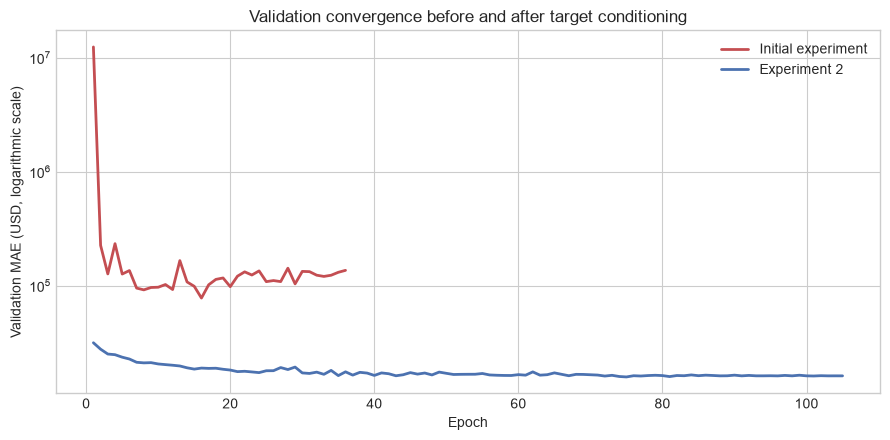

In [5]:
initial_history = json.loads(
    (RESULTS / "training_history.json").read_text(encoding="utf-8")
)
experiment2_history = json.loads(
    (RESULTS / "training_history_experiment2.json").read_text(encoding="utf-8")
)

initial_best = min(initial_history, key=lambda row: row["val_mae"])
experiment2_best = min(experiment2_history, key=lambda row: row["val_mae"])

initial_comparison = pd.DataFrame(
    [
        [
            "Initial experiment",
            "128-64-32",
            43_905,
            initial_best["epoch"],
            initial_best["val_mae"],
            initial_best["val_rmse"],
            initial_best["val_r2"],
        ],
        [
            "Experiment 2",
            "64-32",
            18_881,
            experiment2_best["epoch"],
            experiment2_best["val_mae"],
            experiment2_best["val_rmse"],
            experiment2_best["val_r2"],
        ],
    ],
    columns=["Experiment", "Hidden layers", "Parameters", "Best epoch", "MAE (USD)", "RMSE (USD)", "R2"],
)
display(initial_comparison.style.format({
    "Parameters": "{:,.0f}", "MAE (USD)": "${:,.2f}",
    "RMSE (USD)": "${:,.2f}", "R2": "{:.4f}",
}))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(
    [row["epoch"] for row in initial_history],
    [row["val_mae"] for row in initial_history],
    label="Initial experiment",
    color="#c44e52",
    linewidth=2,
)
ax.plot(
    [row["epoch"] for row in experiment2_history],
    [row["val_mae"] for row in experiment2_history],
    label="Experiment 2",
    color="#4c72b0",
    linewidth=2,
)
ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation MAE (USD, logarithmic scale)")
ax.set_title("Validation convergence before and after target conditioning")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Training Improvements

Experiment 2 introduced train-only standardization of the 261 processed inputs and of $\log(1+\text{SalePrice})$. It also reduced the network to 64-32 hidden units, reduced dropout from 0.20 to 0.05, replaced Adam with AdamW, added initialization matched to ReLU, scheduled the learning rate, and clipped gradients.

These changes reduced validation MAE by 79.69%, from $77,990.05 to $15,837.95. The improvement cannot be attributed to a single modification, which motivated the controlled comparisons and ablations below.

In [6]:
largest_features = pd.DataFrame(
    diagnostics["input_before_additional_standardization"]["largest_feature_maxima"]
).rename(columns={"feature": "Feature", "max_abs": "Maximum absolute value"})

print("Largest processed feature magnitudes before the additional input standardization:")
display(largest_features.head(7).style.format({"Maximum absolute value": "{:,.2f}"}))

improvement = 100 * (initial_best["val_mae"] - experiment2_best["val_mae"]) / initial_best["val_mae"]
print(f"Validation MAE reduction from experiment 1 to experiment 2: {improvement:.2f}%")

Largest processed feature magnitudes before the additional input standardization:


,Feature,Maximum absolute value
0,Misc Val,"15,500.00"
1,BsmtFin SF 2,"1,526.00"
2,Low Qual Fin SF,"1,064.00"
3,Enclosed Porch,"1,012.00"
4,Pool Area,800.00
5,Screen Porch,576.00
6,3Ssn Porch,508.00


Validation MAE reduction from experiment 1 to experiment 2: 79.69%


## 7. Hyperparameter Optimization and Ablation Studies

Experiment 2 is the reference configuration. Seed-42 controlled runs change one factor at a time: dropout, hidden-layer width, weight decay, or learning rate. Two ablations remove additional input standardization or target standardization. All runs use the same train and validation observations.

Removing target standardization is the most damaging intervention. Removing dropout also substantially worsens validation MAE. The 128-64 architecture provides the strongest controlled seed-42 result. The input-standardization ablation reaches a similar minimum MAE to the reference in one seed, but its early optimization and tail-sensitive metrics are worse; therefore, its evidence should not be overstated.

In [7]:
runs = pd.read_csv(RESULTS / "part_a" / "comparison_all_runs.csv")
seed42 = runs[runs["seed"] == 42].copy()
labels = {
    "experiment2_reference": "Experiment 2 reference",
    "e3_no_dropout": "No dropout",
    "e4_wide_128_64": "128-64 architecture",
    "e5_weight_decay_1e4": "Weight decay 1e-4",
    "e6_learning_rate_5e4": "Learning rate 5e-4",
    "a1_no_input_standardization": "No extra input standardization",
    "a2_no_target_standardization": "No target standardization",
}
seed42["Configuration"] = seed42["config_name"].map(labels)
controlled_table = seed42[
    ["Configuration", "hidden_dims", "dropout", "weight_decay", "learning_rate", "best_epoch", "best_val_mae", "best_val_rmse", "best_val_r2"]
].sort_values("best_val_mae")
controlled_table = controlled_table.rename(columns={
    "hidden_dims": "Hidden layers", "dropout": "Dropout", "weight_decay": "Weight decay",
    "learning_rate": "Learning rate", "best_epoch": "Best epoch",
    "best_val_mae": "Validation MAE (USD)", "best_val_rmse": "Validation RMSE (USD)",
    "best_val_r2": "Validation R2",
})
display(controlled_table.style.format({
    "Dropout": "{:.2f}", "Weight decay": "{:.0e}", "Learning rate": "{:.1e}",
    "Validation MAE (USD)": "${:,.2f}", "Validation RMSE (USD)": "${:,.2f}",
    "Validation R2": "{:.4f}",
}))

,Configuration,Hidden layers,Dropout,Weight decay,Learning rate,Best epoch,Validation MAE (USD),Validation RMSE (USD),Validation R2
2,128-64 architecture,"[128, 64]",0.05,1e-05,1.0e-03,83,"$14,051.46","$20,626.19",0.9452
3,Weight decay 1e-4,"[64, 32]",0.05,1e-04,1.0e-03,81,"$15,534.41","$23,628.12",0.9280
5,No extra input standardization,"[64, 32]",0.05,1e-05,1.0e-03,75,"$15,696.59","$26,301.79",0.9108
0,Experiment 2 reference,"[64, 32]",0.05,1e-05,1.0e-03,75,"$15,837.95","$24,233.63",0.9243
4,Learning rate 5e-4,"[64, 32]",0.05,1e-05,5.0e-04,61,"$16,341.55","$25,099.41",0.9188
1,No dropout,"[64, 32]",0.00,1e-05,1.0e-03,66,"$19,330.28","$28,932.34",0.8921
6,No target standardization,"[64, 32]",0.05,1e-05,1.0e-03,152,"$34,600.95","$56,754.42",0.5847


**Training and validation loss for the controlled seed-42 runs**

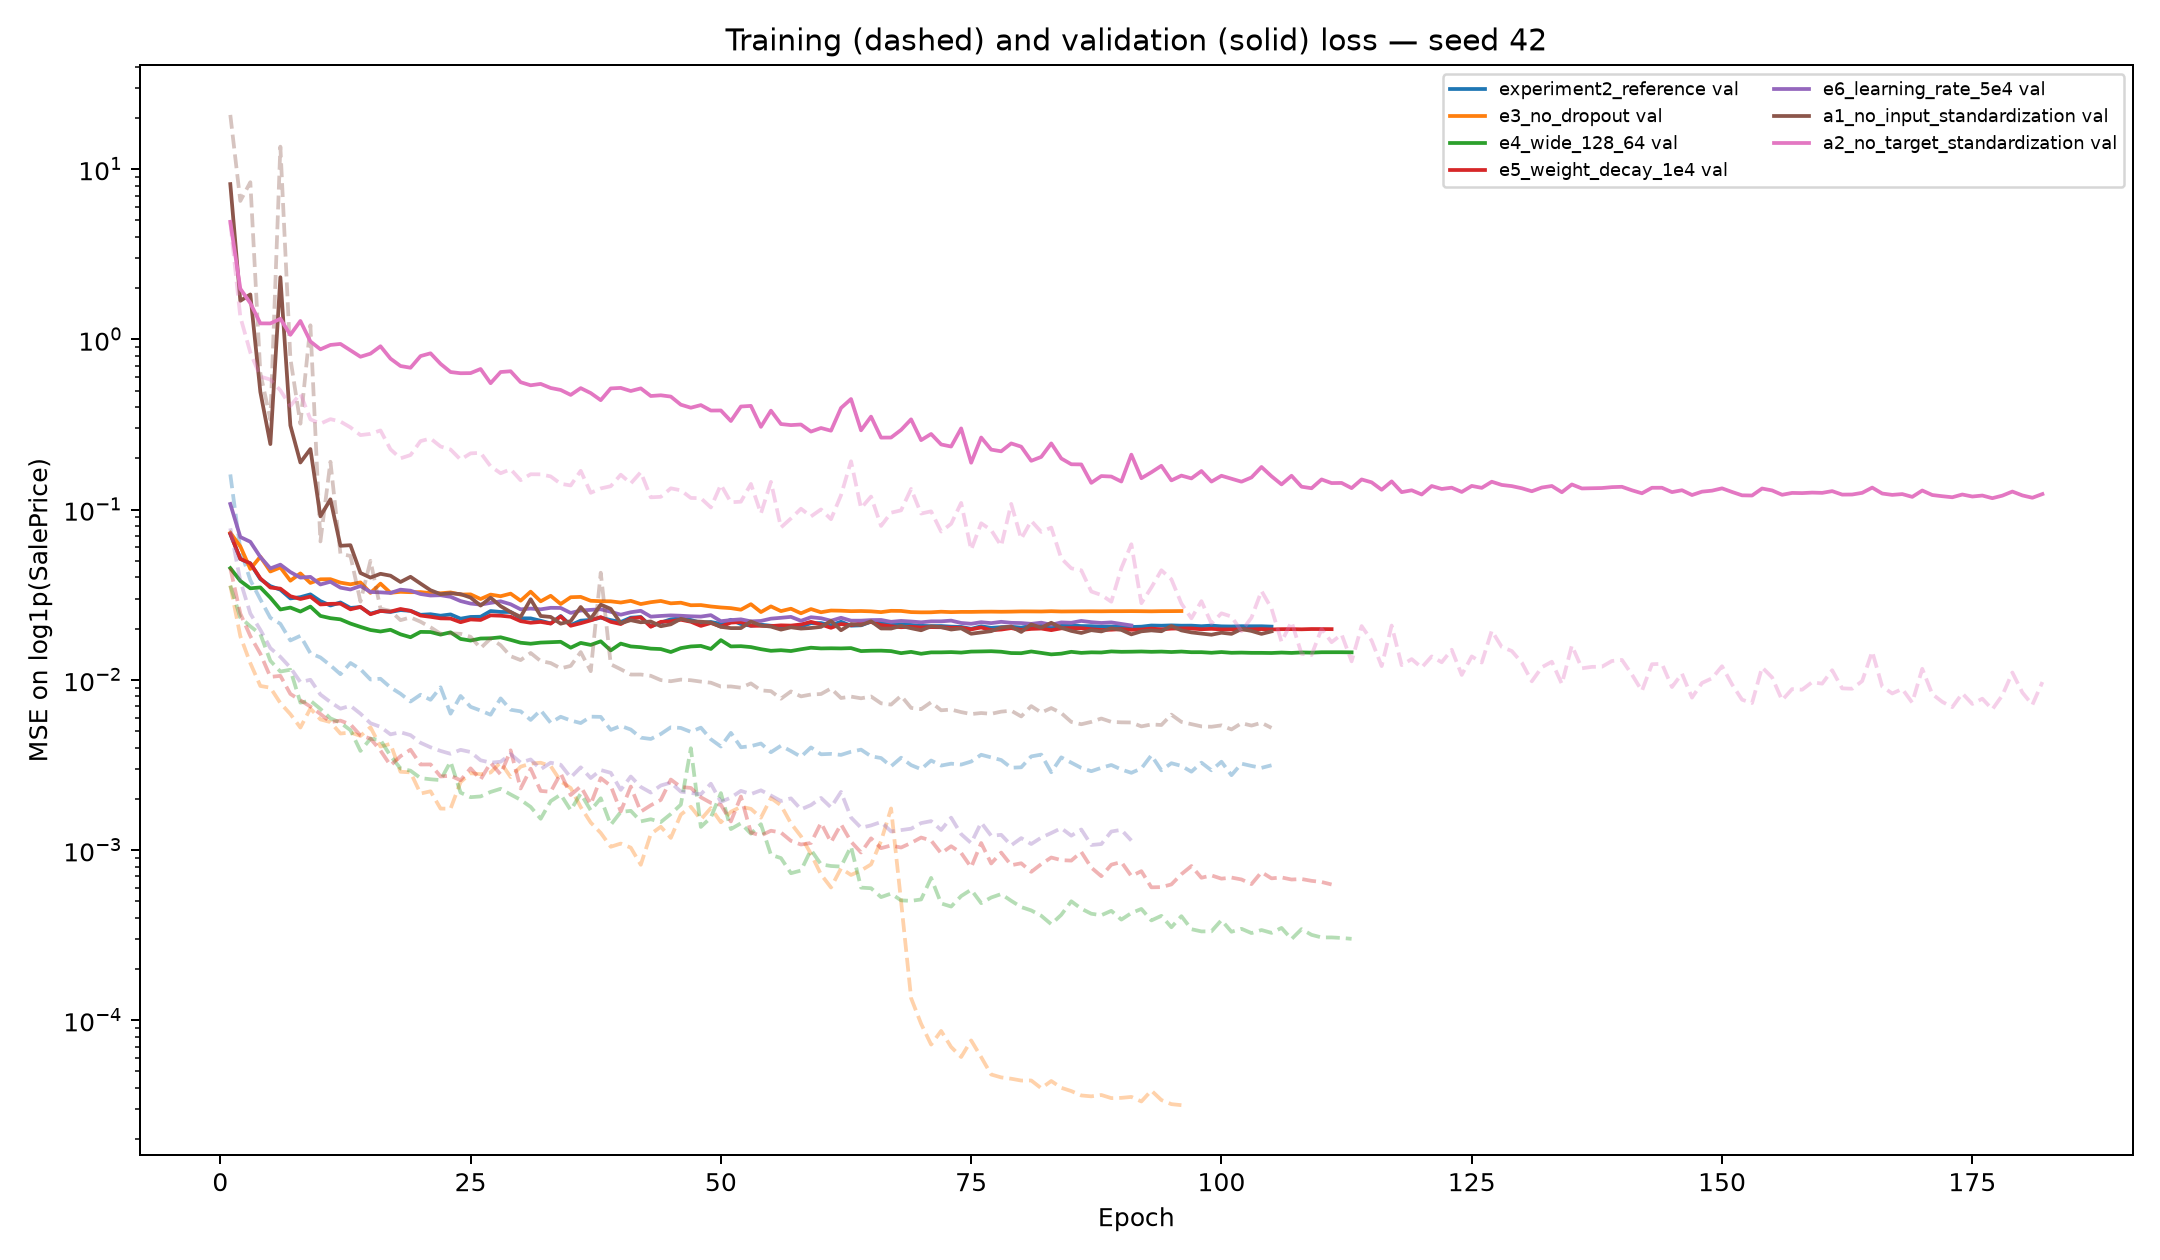

**Best validation MAE across the controlled configurations**

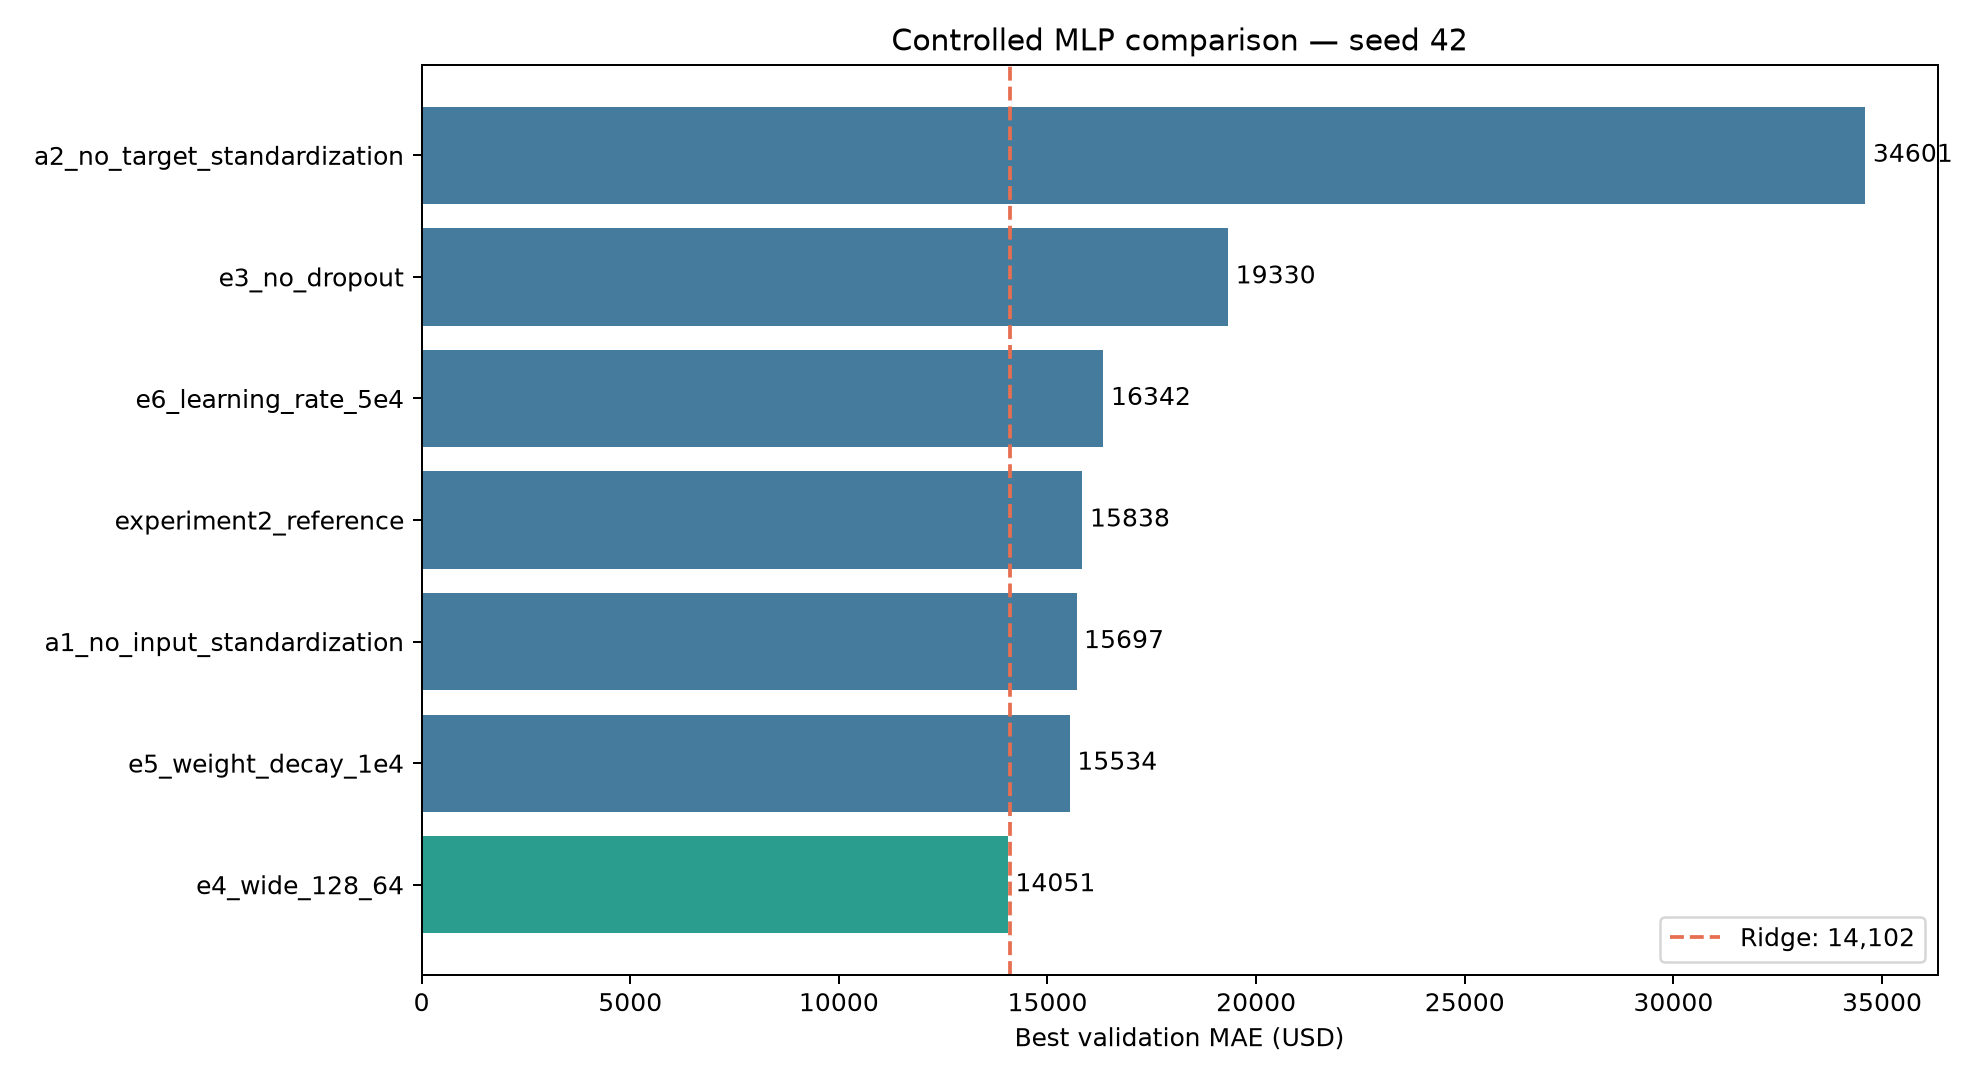

In [8]:
display(Markdown("**Training and validation loss for the controlled seed-42 runs**"))
display(Image(filename=str(FIGURES / "part_a" / "loss_curves_seed42.png"), width=1050))

display(Markdown("**Best validation MAE across the controlled configurations**"))
display(Image(filename=str(FIGURES / "part_a" / "mae_comparison_seed42.png"), width=1000))

## 8. Multi-Seed Stability Analysis

The reference, 128-64 architecture, and stronger-weight-decay configuration were repeated with seeds 7, 42, and 2026. The 128-64 model was selected by the lowest **mean validation MAE**, not by the single best run. Its mean was $14,238.79 with a standard deviation of $183.95, considerably lower variability than the alternatives.

Although weight decay $10^{-4}$ produced the lowest individual validation MAE under seed 7, selecting that run alone would be optimistic because the same configuration varied substantially across seeds.

,Configuration,Seeds,MAE mean (USD),MAE std. (USD),Minimum MAE,Maximum MAE,RMSE mean (USD),R2 mean
0,128-64 architecture,"[42, 7, 2026]","$14,238.79",$183.95,"$14,051.46","$14,419.17","$20,779.54",0.9443
1,Weight decay 1e-4,"[42, 7, 2026]","$14,379.15","$1,037.55","$13,526.67","$15,534.41","$21,415.30",0.9405
2,Experiment 2 reference,"[42, 7, 2026]","$14,695.31","$1,021.94","$13,868.75","$15,837.95","$21,669.05",0.9390


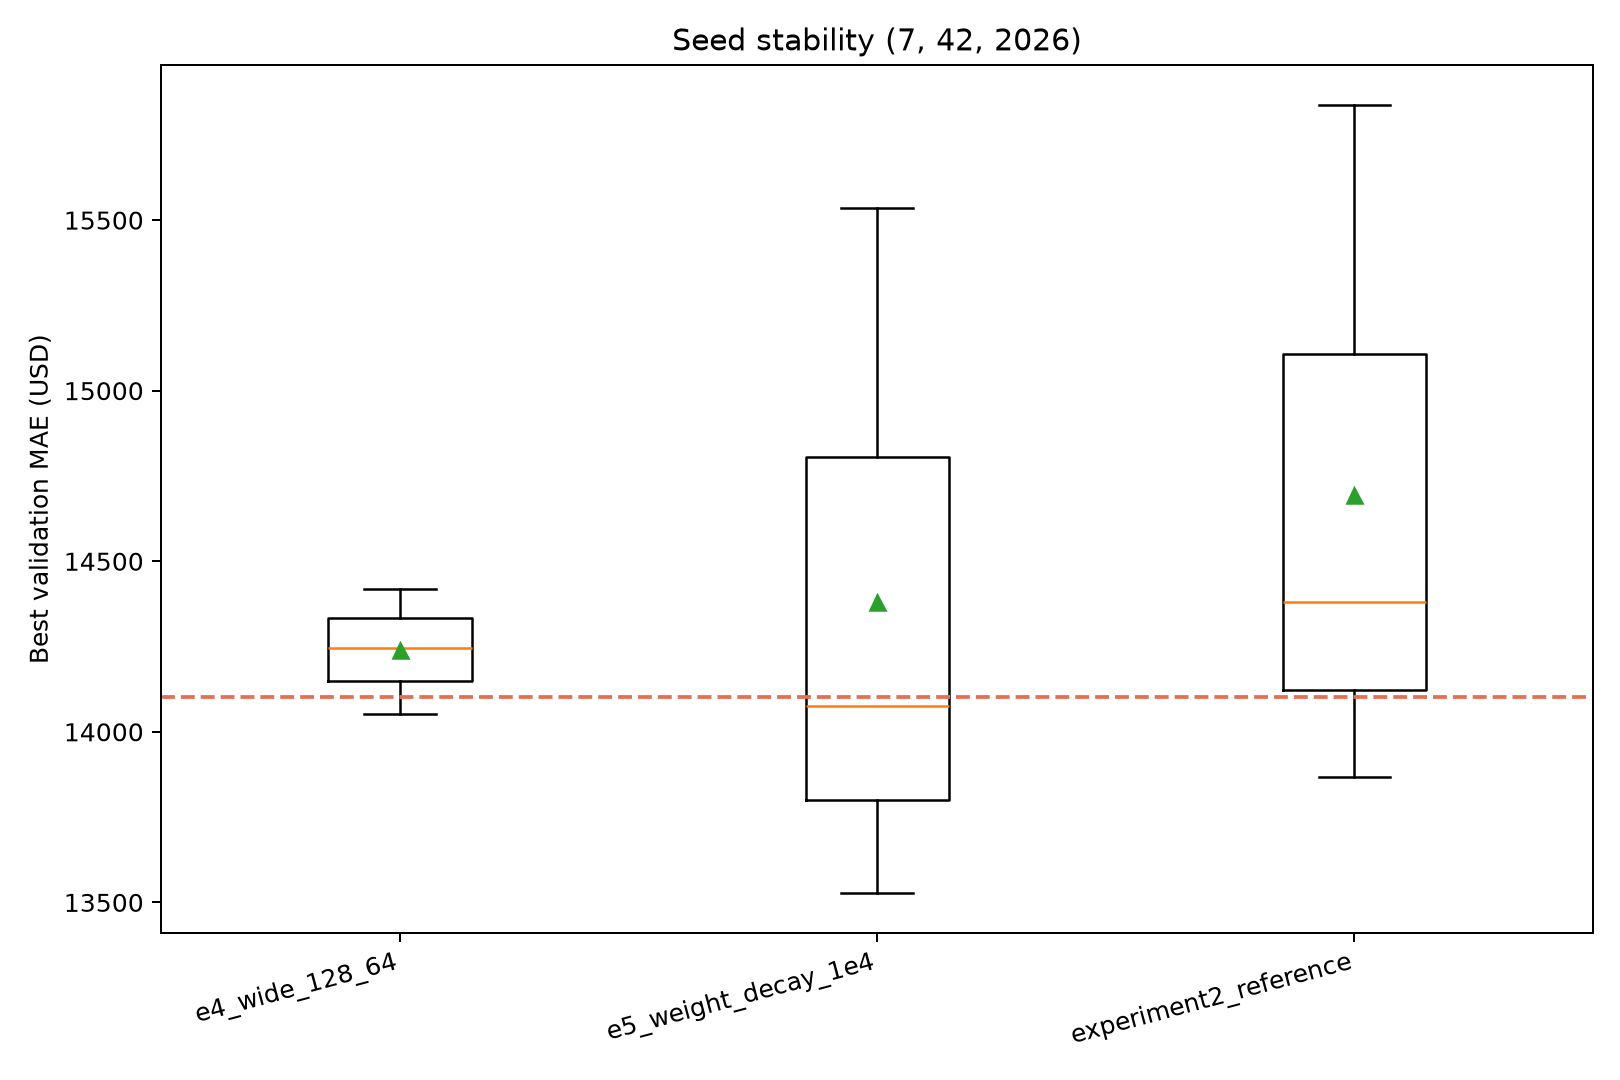

In [9]:
stability = pd.DataFrame(json.loads(
    (RESULTS / "part_a" / "stability_summary.json").read_text(encoding="utf-8")
))
multi_seed = stability[stability["n_seeds"] == 3].copy()
multi_seed["Configuration"] = multi_seed["config_name"].map(labels)
multi_seed_table = multi_seed[
    ["Configuration", "seeds", "mae_mean", "mae_std", "mae_min", "mae_max", "rmse_mean", "r2_mean"]
].rename(columns={
    "seeds": "Seeds", "mae_mean": "MAE mean (USD)", "mae_std": "MAE std. (USD)",
    "mae_min": "Minimum MAE", "mae_max": "Maximum MAE", "rmse_mean": "RMSE mean (USD)",
    "r2_mean": "R2 mean",
})
display(multi_seed_table.style.format({
    "MAE mean (USD)": "${:,.2f}", "MAE std. (USD)": "${:,.2f}",
    "Minimum MAE": "${:,.2f}", "Maximum MAE": "${:,.2f}",
    "RMSE mean (USD)": "${:,.2f}", "R2 mean": "{:.4f}",
}))

display(Image(filename=str(FIGURES / "part_a" / "seed_stability.png"), width=900))

## 9. Final Test Evaluation

After validation-only selection, the seed-42 checkpoint of the 128-64 configuration was frozen and loaded without retraining. Evaluation reused the 440 test indices in `data/splits.json`, the Workshop 1 preprocessing fitted on training, and the normalization statistics stored in the checkpoint. The inverse target transformation was applied before calculating dollar-scale metrics.

The MLP achieved test MAE $14,666.23, RMSE $34,133.71, $R^2=0.8483$, and log-scale RMSE 0.1254. Its test MAE is 4.38% above its validation MAE, indicating a moderate generalization gap.

In [10]:
test_metrics = pd.read_csv(RESULTS / "final_test" / "model_comparison_test.csv")
display(test_metrics.style.format({
    "MAE": "${:,.2f}", "RMSE": "${:,.2f}", "R2": "{:.4f}", "RMSE_log": "{:.4f}",
}))

final_audit = json.loads(
    (RESULTS / "final_test" / "final_test_metrics.json").read_text(encoding="utf-8")
)
test_identity = pd.DataFrame(
    {
        "Audit item": [
            "Selection frozen before test", "Test observations", "Selected seed",
            "Split-index SHA-256", "Targets SHA-256",
        ],
        "Verified value": [
            final_audit["selection_frozen_before_test"],
            final_audit["test_set"]["n_observations"],
            final_audit["selected_seed"],
            final_audit["test_set"]["split_indices_sha256"],
            final_audit["test_set"]["targets_sha256"],
        ],
    }
)
display(test_identity)

,Model,MAE,RMSE,R2,RMSE_log
0,Deep Learning MLP,"$14,666.23","$34,133.71",0.8483,0.1254
1,Ridge Regression,"$15,031.51","$44,511.47",0.7421,0.1254
2,Random Forest,"$16,700.76","$31,325.66",0.8723,0.1325
3,Gradient Boosting,"$14,876.80","$31,939.29",0.8672,0.1208


,Audit item,Verified value
0,Selection frozen before test,True
1,Test observations,440
2,Selected seed,42
3,Split-index SHA-256,90596065fefdcddd60780800d95468600b2c62e6ab0bfd...
4,Targets SHA-256,6dbf57836d6e25257458e808e1de05dab1e07f199bb539...


## 10. Comparison with Workshop 1 Baselines

The MLP obtains the lowest test MAE among the four models: it improves Ridge Regression by 2.43%, Random Forest by 12.18%, and Gradient Boosting by 1.42%. This is a narrow advantage in typical absolute dollar error, not universal superiority.

Random Forest has the best RMSE and $R^2$, while Gradient Boosting has the best log-scale RMSE. These differences show that metric choice matters: MAE weights every absolute error linearly, whereas RMSE is more sensitive to rare large mistakes.

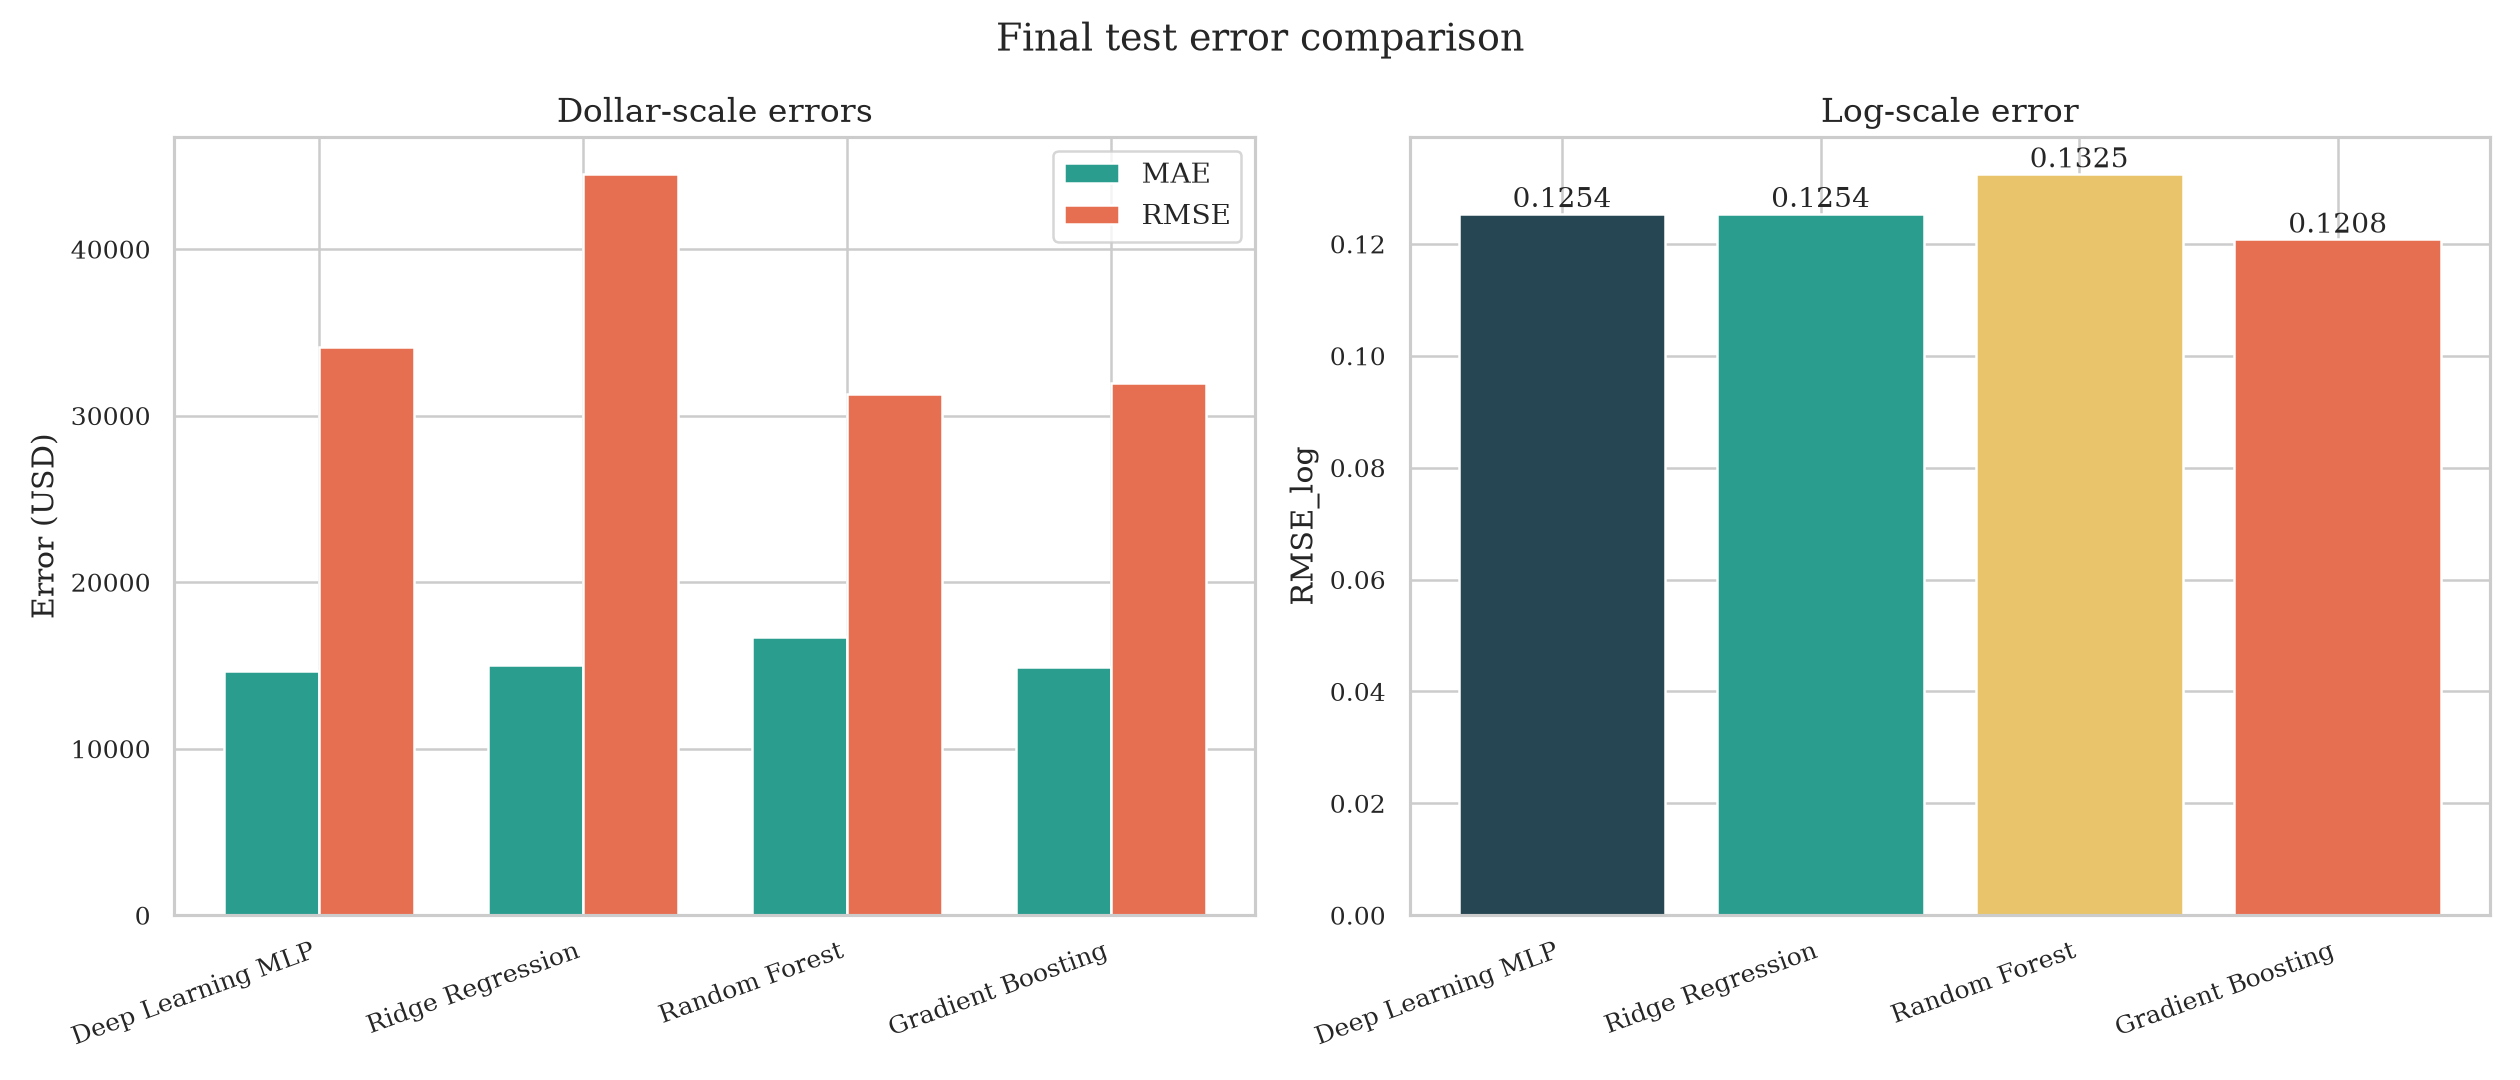

In [11]:
display(Image(filename=str(FIGURES / "final_test" / "error_comparison_test.png"), width=1050))

## 11. Residual Analysis and Prediction Visualization

Actual-versus-predicted plots show that most test predictions follow the identity line in the common price range. Residual plots reveal increasing dispersion at high predicted prices and a small number of high-leverage errors.

The largest MLP error occurs at split index 2181 (PID 908154205). The actual price is $184,750, while the MLP predicts approximately $775,256, producing a residual near -$590,506. Squaring this error gives it disproportionate influence on RMSE and $R^2$, which helps explain why the MLP leads in MAE but trails the tree ensembles on tail-sensitive metrics.

**Actual and predicted prices on the fixed test partition**

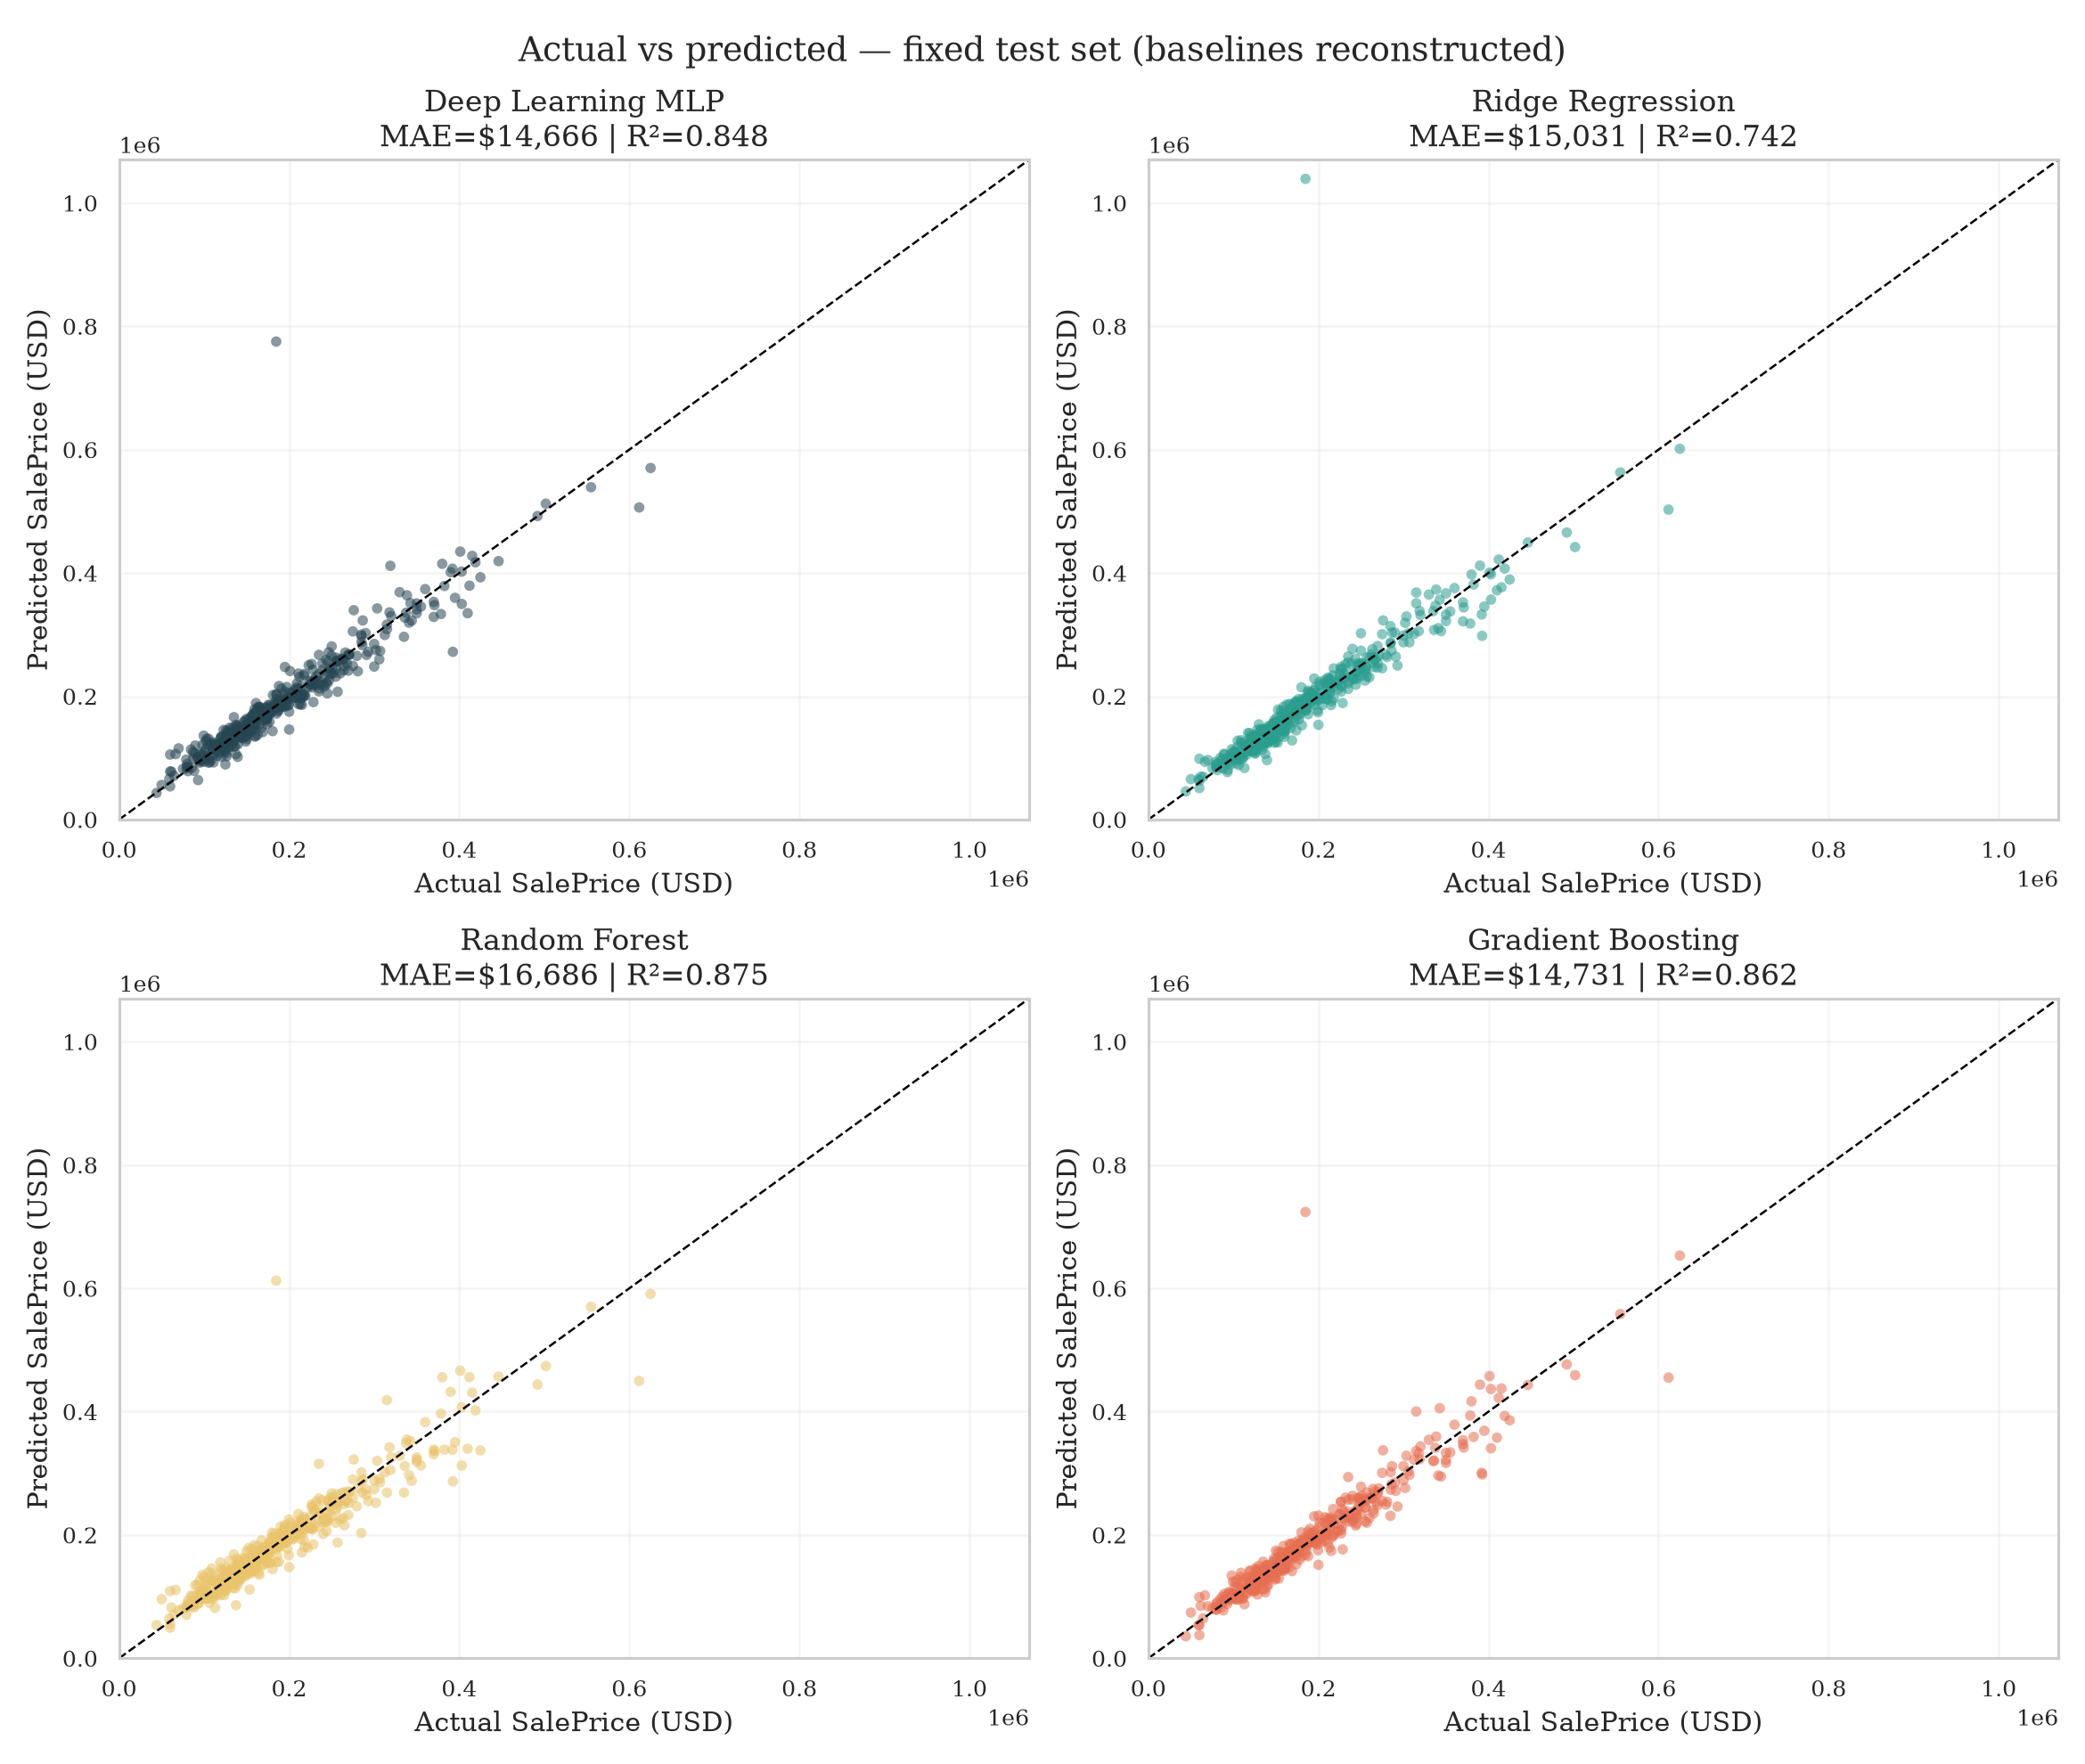

**Residual patterns and residual distributions**

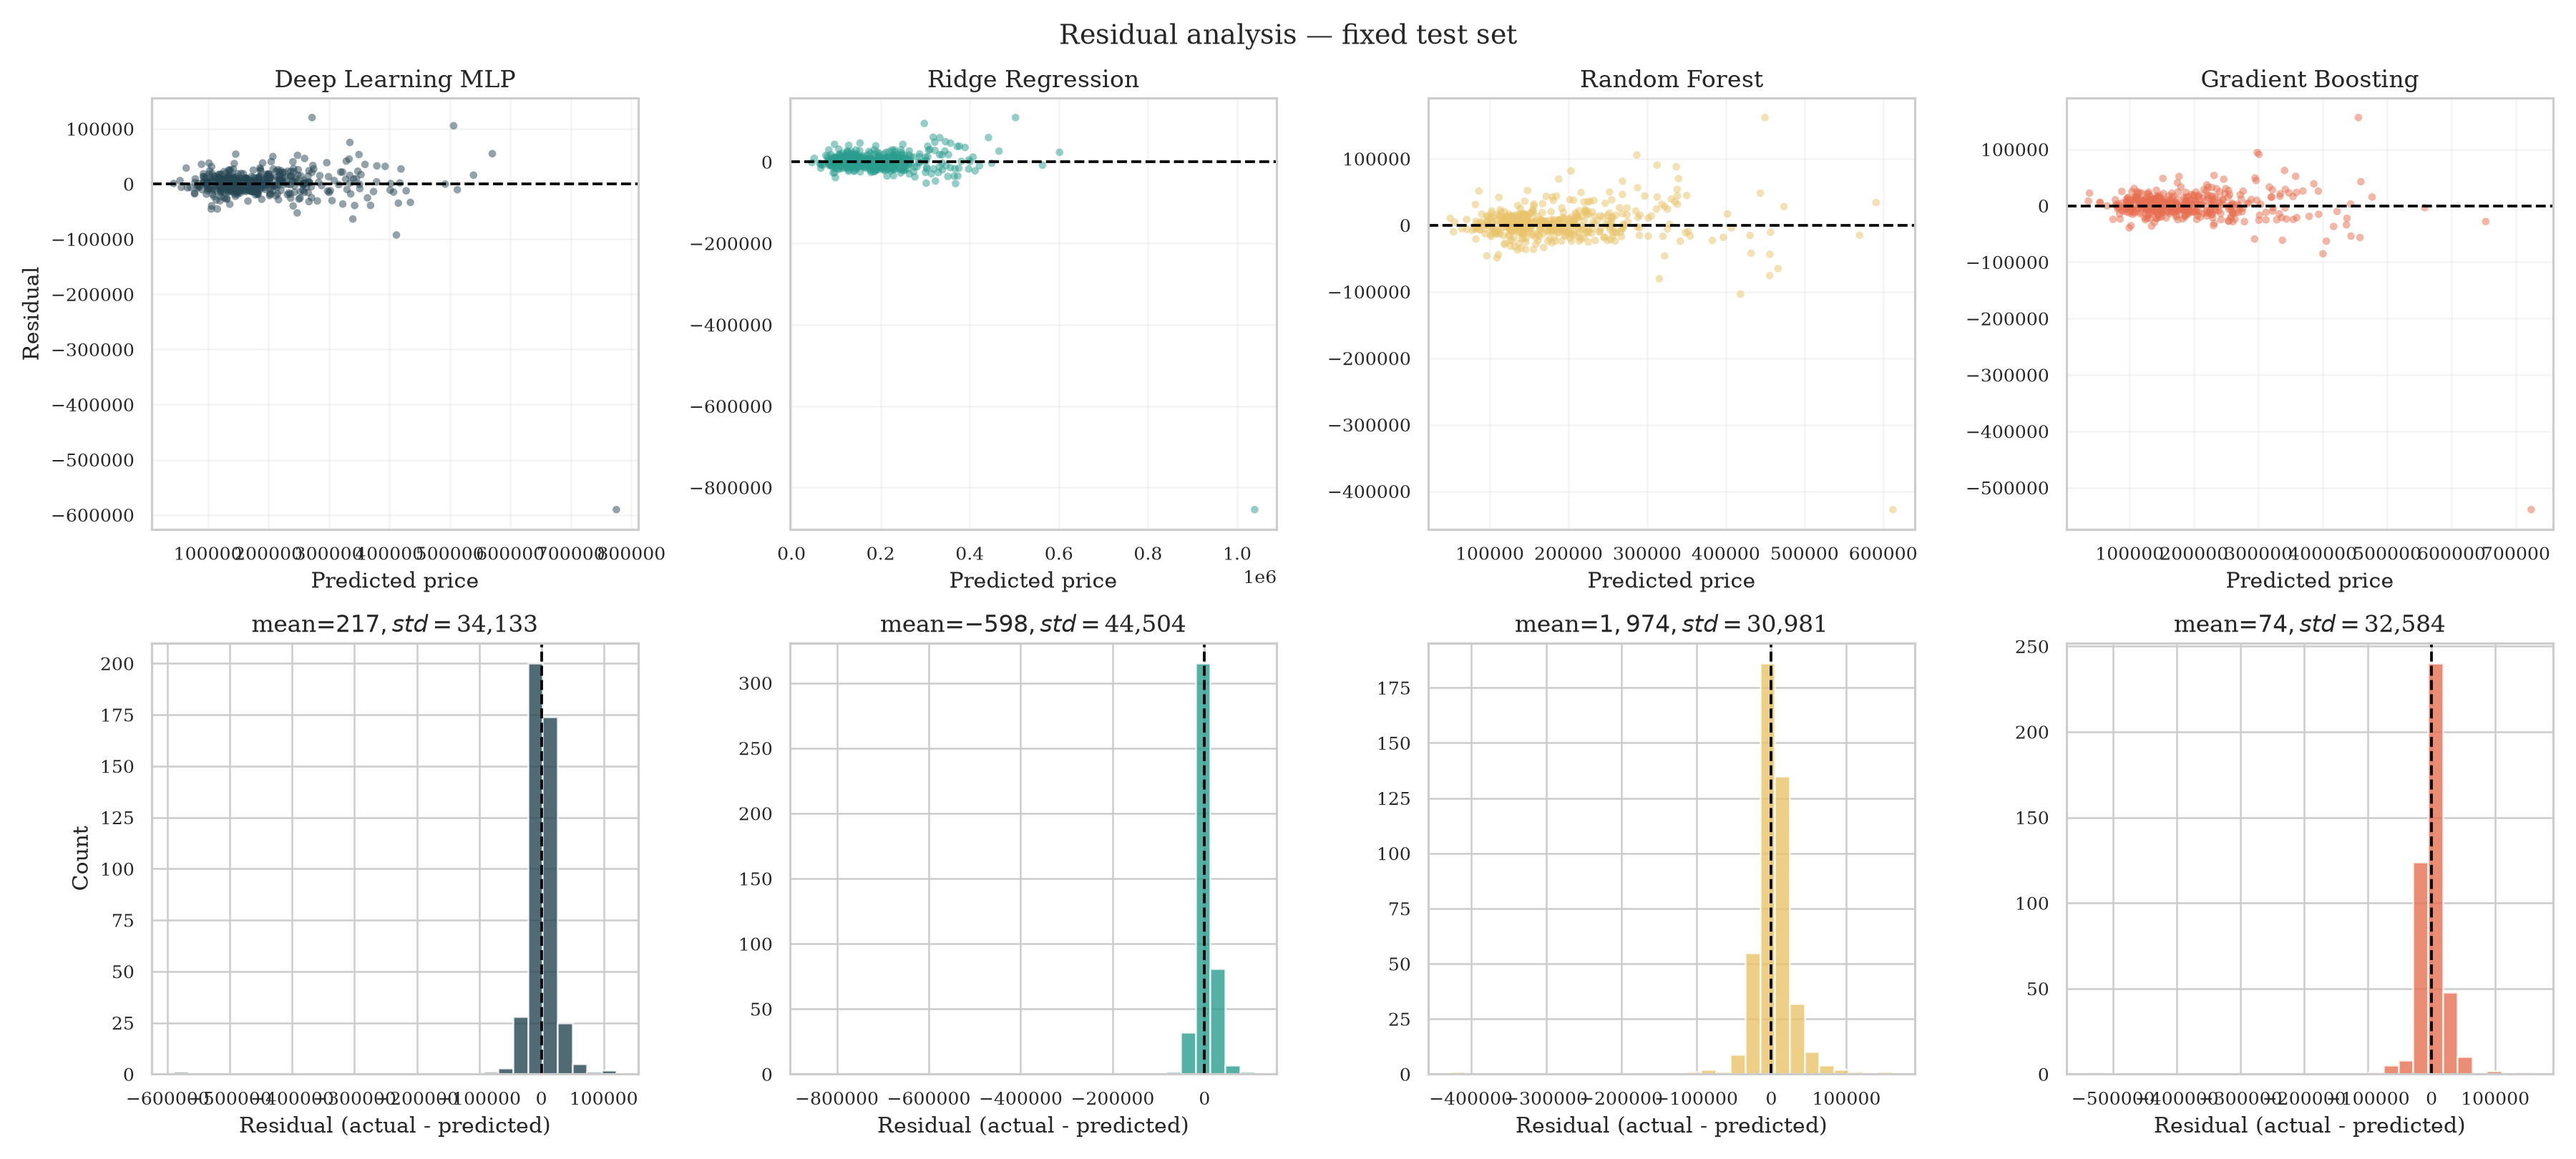

In [12]:
display(Markdown("**Actual and predicted prices on the fixed test partition**"))
display(Image(filename=str(FIGURES / "final_test" / "actual_vs_predicted_test.png"), width=1050))

display(Markdown("**Residual patterns and residual distributions**"))
display(Image(filename=str(FIGURES / "final_test" / "residual_analysis_test.png"), width=1150))

In [13]:
predictions = pd.read_csv(RESULTS / "final_test" / "test_predictions.csv")
extreme = predictions.loc[predictions["deep_learning_mlp_residual"].abs().idxmax()]

extreme_case = pd.DataFrame(
    {
        "Field": ["Split index", "PID", "Actual price", "MLP prediction", "Residual (actual - predicted)"],
        "Value": [
            int(extreme["split_index"]),
            int(extreme["PID"]),
            f"${extreme['SalePrice_actual']:,.2f}",
            f"${extreme['deep_learning_mlp_predicted']:,.2f}",
            f"${extreme['deep_learning_mlp_residual']:,.2f}",
        ],
    }
)
display(extreme_case)

audit_rows = []
for model_name, values in final_audit["baseline_reconstruction_audit"].items():
    audit_rows.append(
        {
            "Baseline": model_name,
            "Historical MAE (USD)": values["stored_test_metrics"]["MAE"],
            "Reconstructed MAE (USD)": values["reconstructed_test_metrics"]["MAE"],
            "Absolute difference (USD)": values["absolute_difference"]["MAE"],
        }
    )
audit_table = pd.DataFrame(audit_rows)
display(audit_table.style.format({
    "Historical MAE (USD)": "${:,.2f}", "Reconstructed MAE (USD)": "${:,.2f}",
    "Absolute difference (USD)": "${:,.2f}",
}))

,Field,Value
0,Split index,2181
1,PID,908154205
2,Actual price,"$184,750.00"
3,MLP prediction,"$775,256.31"
4,Residual (actual - predicted),"$-590,506.31"


,Baseline,Historical MAE (USD),Reconstructed MAE (USD),Absolute difference (USD)
0,Ridge Regression,"$15,031.51","$15,030.79",$0.72
1,Random Forest,"$16,700.76","$16,686.01",$14.75
2,Gradient Boosting,"$14,876.80","$14,731.47",$145.34


## 12. Discussion and Conclusions

The experiments show that optimization conditioning was more important than simply increasing model complexity. Train-only standardization of the log target transformed an unstable initial optimization problem into a competitive regression model. Additional input standardization improved early stability and tail behavior, while the ablation results strongly support retaining target standardization and light dropout. Increasing the hidden widths from 64-32 to 128-64 produced the most stable validation improvement across the three evaluated seeds.

The selected MLP achieved the lowest test MAE, but it did not dominate all metrics. Random Forest and Gradient Boosting were more robust under squared-error criteria, and one extreme MLP prediction materially increased RMSE. Therefore, the result supports the limited conclusion that the MLP improved average absolute dollar error on this fixed split; it does not establish general superiority over classical models.

The evaluation has several limitations. The dataset is small for a 41,857-parameter neural model, seed repetitions share one fixed split, only three configurations received multi-seed evaluation, and reconstructed baseline predictions show small software-version differences from the immutable Workshop 1 metrics. The observed test set must not be reused for additional hyperparameter tuning. Future work should use a new validation protocol to evaluate robust losses, alternative tabular architectures, and uncertainty-aware predictions.

### Reproducibility Record

- The split file is immutable and contains 2,050 training, 440 validation, and 440 test indices.
- The selected checkpoint stores the architecture, seed, feature order, training-only input statistics, and training-only target statistics.
- The checkpoint was selected before test evaluation and is loaded without retraining.
- The saved final-evaluation audit confirms identical predictions from two independent checkpoint loads.
- Seven final-evaluation checks and three training utility tests passed in the recorded evaluation workflow.
- Diagnostic baseline predictions were reconstructed with frozen Workshop 1 definitions; the definitive comparison table retains the historical Workshop 1 metrics because the current software environment introduces small numerical differences.